In [2]:
import json
import time
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

# Formatting & reproducibility
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.bbox"] = "tight"
sns.set_theme(style="whitegrid")

# Resolve project paths whether notebook is run from root or analysis/
CWD = Path.cwd()
BASE_DIR = CWD.parent if CWD.name == "analysis" else CWD
RESULT_DIR = BASE_DIR / "results"
FIG_DIR = RESULT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Approved chronological split boundaries
TRAIN_START, TRAIN_END = "2025-02-08", "2025-11-26"
VAL_START, VAL_END     = "2025-11-27", "2026-01-01"
TEST_START, TEST_END   = "2026-01-02", "2026-02-07"

# Verify required source artifacts exist
REQUIRED_FILES = [
    RESULT_DIR / "fact_delay.parquet",
    RESULT_DIR / "combined_schedule_imputed.csv",
    RESULT_DIR / "stop_alignment_map.csv",
    RESULT_DIR / "dim_train.csv",
    RESULT_DIR / "dim_station.csv",
    RESULT_DIR / "dim_date.csv",
]
for fp in REQUIRED_FILES:
    assert fp.exists(), f"Missing required validated artifact: {fp}"

# Use an in-memory DuckDB session reading existing validated artifacts (zero modification to warehouse files)
con = duckdb.connect(database=":memory:")
con.execute("PRAGMA threads=4;")

# Inspect fact_delay.parquet schema to handle date_id vs date column naming seamlessly
fact_cols = [
    r[0] for r in con.execute(
        f"DESCRIBE SELECT * FROM read_parquet('{str(RESULT_DIR / 'fact_delay.parquet')}')"
    ).fetchall()
]
DATE_COL = "date_id" if "date_id" in fact_cols else "date"
print(f"Detected date column in fact_delay.parquet: '{DATE_COL}'")
print(f"Total columns in fact_delay.parquet ({len(fact_cols)}): {fact_cols}")

# Register read-only views over validated artifacts
con.execute(f"""
CREATE OR REPLACE VIEW fact_delay AS
SELECT
    CAST({DATE_COL} AS DATE) AS date_id,
    * EXCLUDE ({DATE_COL})
FROM read_parquet('{str(RESULT_DIR / 'fact_delay.parquet')}');

CREATE OR REPLACE VIEW dim_train AS
SELECT * FROM read_csv_auto('{str(RESULT_DIR / 'dim_train.csv')}');

CREATE OR REPLACE VIEW dim_station AS
SELECT * FROM read_csv_auto('{str(RESULT_DIR / 'dim_station.csv')}');

CREATE OR REPLACE VIEW dim_date AS
SELECT CAST(date_id AS DATE) AS date_id, * EXCLUDE (date_id)
FROM read_csv_auto('{str(RESULT_DIR / 'dim_date.csv')}');

CREATE OR REPLACE VIEW schedule_imputed AS
SELECT * FROM read_csv_auto('{str(RESULT_DIR / 'combined_schedule_imputed.csv')}');

CREATE OR REPLACE VIEW stop_alignment_map AS
SELECT * FROM read_csv_auto('{str(RESULT_DIR / 'stop_alignment_map.csv')}');
""")

# Governance Check 1: Row conservation, grain integrity, and chronological partition coverage
partition_audit = con.execute(f"""
SELECT
    CASE
        WHEN date_id BETWEEN DATE '{TRAIN_START}' AND DATE '{TRAIN_END}' THEN '1_Train (2025-02-08 to 2025-11-26)'
        WHEN date_id BETWEEN DATE '{VAL_START}'   AND DATE '{VAL_END}'   THEN '2_Validation (2025-11-27 to 2026-01-01)'
        WHEN date_id BETWEEN DATE '{TEST_START}'  AND DATE '{TEST_END}'  THEN '3_Test (2026-01-02 to 2026-02-07)'
        ELSE 'OUT_OF_BOUNDS'
    END AS chronological_partition,
    COUNT(DISTINCT date_id) AS n_days,
    COUNT(*) AS total_rows,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 4) AS pct_total_rows,
    SUM(CASE WHEN has_schedule THEN 1 ELSE 0 END) AS has_schedule_rows,
    SUM(CASE WHEN NOT is_imputed THEN 1 ELSE 0 END) AS observed_rows,
    SUM(CASE WHEN has_schedule AND NOT is_imputed THEN 1 ELSE 0 END) AS pred_eligible_obs_rows,
    SUM(CASE WHEN has_schedule AND is_imputed THEN 1 ELSE 0 END) AS pred_eligible_imp_rows
FROM fact_delay
GROUP BY 1
ORDER BY 1;
""").df()

print("\n=== CHRONOLOGICAL PARTITION & GOVERNANCE AUDIT ===")
print(partition_audit.to_string(index=False))

assert "OUT_OF_BOUNDS" not in partition_audit["chronological_partition"].values, "Found dates outside 2025-02-08..2026-02-07!"
assert int(partition_audit["total_rows"].sum()) == 36614824, "Row conservation check failed!"
assert int(partition_audit["n_days"].sum()) == 365, "Total calendar days must equal 365!"

Detected date column in fact_delay.parquet: 'date_id'
Total columns in fact_delay.parquet (23): ['date_id', 'train_no', 'station_no', 'station_name', 'delay', 'delay_type', 'punctuality_band', 'severity', 'is_imputed', 'has_schedule', 'alignment_cls', 'sched_station_no', 'distance_from_origin', 'inter_station_distance', 'arrival_day', 'arrival_time', 'departure_day', 'departure_time', 'scheduled_arrival_min', 'scheduled_departure_min', 'scheduled_halt_minutes', 'scheduled_travel_min_from_origin', 'is_schedule_time_imputed']

=== CHRONOLOGICAL PARTITION & GOVERNANCE AUDIT ===
                chronological_partition  n_days  total_rows  pct_total_rows  has_schedule_rows  observed_rows  pred_eligible_obs_rows  pred_eligible_imp_rows
     1_Train (2025-02-08 to 2025-11-26)     292    29371388         80.2172         28683754.0     28502262.0              28264191.0                419563.0
2_Validation (2025-11-27 to 2026-01-01)      36     3583894          9.7881          3500548.0      34

In [3]:
# Validate schedule sequence continuity and stop_alignment_map uniqueness before graph construction
sched_audit = con.execute("""
WITH sched_ordered AS (
    SELECT
        train_no,
        station_no,
        station_name,
        distance_from_origin,
        LAG(station_no) OVER (PARTITION BY train_no ORDER BY station_no) AS prev_station_no,
        LAG(distance_from_origin) OVER (PARTITION BY train_no ORDER BY station_no) AS prev_dist
    FROM schedule_imputed
)
SELECT
    COUNT(*) AS total_sched_rows,
    COUNT(DISTINCT train_no) AS unique_sched_trains,
    COUNT(DISTINCT station_name) AS unique_sched_stations,
    SUM(CASE WHEN prev_station_no IS NULL AND station_no != 1 THEN 1 ELSE 0 END) AS non_unit_origins,
    SUM(CASE WHEN prev_station_no IS NOT NULL AND station_no != prev_station_no + 1 THEN 1 ELSE 0 END) AS sequence_gaps,
    SUM(CASE WHEN prev_dist IS NOT NULL AND distance_from_origin < prev_dist THEN 1 ELSE 0 END) AS negative_distance_deltas
FROM sched_ordered;
""").df()

align_audit = con.execute("""
SELECT
    COUNT(*) AS total_alignment_stops,
    SUM(CASE WHEN sched_station_no IS NOT NULL THEN 1 ELSE 0 END) AS aligned_stops,
    SUM(CASE WHEN sched_station_no IS NULL THEN 1 ELSE 0 END) AS unaligned_stops,
    COUNT(*) - COUNT(DISTINCT (train_no, delay_station_no)) AS dup_delay_keys,
    SUM(CASE WHEN sched_station_no IS NOT NULL THEN 1 ELSE 0 END)
      - COUNT(DISTINCT CASE WHEN sched_station_no IS NOT NULL THEN (train_no, sched_station_no) END) AS dup_sched_targets
FROM stop_alignment_map;
""").df()

print("=== SCHEDULE CONTINUITY AUDIT ===")
print(sched_audit.to_string(index=False))
print("\n=== STOP ALIGNMENT MAP AUDIT ===")
print(align_audit.to_string(index=False))

assert int(sched_audit["dup_delay_keys"].iloc[0]) == 0 if "dup_delay_keys" in sched_audit else int(align_audit["dup_delay_keys"].iloc[0]) == 0
assert int(align_audit["dup_sched_targets"].iloc[0]) == 0, "Duplicate target (train_no, sched_station_no) detected!"

=== SCHEDULE CONTINUITY AUDIT ===
 total_sched_rows  unique_sched_trains  unique_sched_stations  non_unit_origins  sequence_gaps  negative_distance_deltas
           172112                 8673                   8629               0.0            0.0                       0.0

=== STOP ALIGNMENT MAP AUDIT ===
 total_alignment_stops  aligned_stops  unaligned_stops  dup_delay_keys  dup_sched_targets
                141646       137443.0           4203.0               0                0.0


In [7]:
t0 = time.time()

# 1. Extract static directed station-to-station edges from combined_schedule_imputed.csv
static_edges_df = con.execute("""
WITH sched_seq AS (
    SELECT
        CAST(train_no AS INTEGER) AS train_no,
        CAST(station_no AS INTEGER) AS from_sched_station_no,
        CAST(station_name AS VARCHAR) AS from_station,
        CAST(distance_from_origin AS DOUBLE) AS from_dist_km,
        ((CAST(arrival_day AS INTEGER) - 1) * 1440
         + CAST(SPLIT_PART(CAST(arrival_time AS VARCHAR), ':', 1) AS INTEGER) * 60
         + CAST(SPLIT_PART(CAST(arrival_time AS VARCHAR), ':', 2) AS INTEGER)) AS from_arr_min,
        ((CAST(departure_day AS INTEGER) - 1) * 1440
         + CAST(SPLIT_PART(CAST(departure_time AS VARCHAR), ':', 1) AS INTEGER) * 60
         + CAST(SPLIT_PART(CAST(departure_time AS VARCHAR), ':', 2) AS INTEGER)) AS from_dep_min,
        LEAD(CAST(station_no AS INTEGER)) OVER (PARTITION BY train_no ORDER BY CAST(station_no AS INTEGER)) AS to_sched_station_no,
        LEAD(CAST(station_name AS VARCHAR)) OVER (PARTITION BY train_no ORDER BY CAST(station_no AS INTEGER)) AS to_station,
        LEAD(CAST(distance_from_origin AS DOUBLE)) OVER (PARTITION BY train_no ORDER BY CAST(station_no AS INTEGER)) AS to_dist_km,
        LEAD(
            (CAST(arrival_day AS INTEGER) - 1) * 1440
            + CAST(SPLIT_PART(CAST(arrival_time AS VARCHAR), ':', 1) AS INTEGER) * 60
            + CAST(SPLIT_PART(CAST(arrival_time AS VARCHAR), ':', 2) AS INTEGER)
        ) OVER (PARTITION BY train_no ORDER BY CAST(station_no AS INTEGER)) AS to_arr_min
    FROM schedule_imputed
)
SELECT
    from_station,
    to_station,
    COUNT(DISTINCT train_no) AS scheduled_train_count,
    COUNT(*) AS scheduled_transition_rows,
    ROUND(AVG(GREATEST(to_dist_km - from_dist_km, 0.0)), 4) AS mean_sched_segment_dist_km,
    ROUND(MEDIAN(GREATEST(to_dist_km - from_dist_km, 0.0)), 4) AS median_sched_segment_dist_km,
    ROUND(AVG(GREATEST(to_arr_min - from_dep_min, 1.0)), 4) AS mean_sched_running_min,
    ROUND(MEDIAN(GREATEST(to_arr_min - from_dep_min, 1.0)), 4) AS median_sched_running_min
FROM sched_seq
WHERE to_station IS NOT NULL
  AND to_sched_station_no = from_sched_station_no + 1
  AND from_station != to_station
GROUP BY from_station, to_station
ORDER BY scheduled_train_count DESC, from_station, to_station;
""").df()

# 2. Extract static per-station schedule counts
static_station_sched_df = con.execute("""
WITH bounds AS (
    SELECT
        CAST(train_no AS INTEGER) AS train_no,
        CAST(station_no AS INTEGER) AS station_no,
        CAST(station_name AS VARCHAR) AS station_name,
        MAX(CAST(station_no AS INTEGER)) OVER (PARTITION BY train_no) AS max_station_no
    FROM schedule_imputed
)
SELECT
    b.station_name,
    ds.station_full_name,
    ds.station_zone,
    COUNT(DISTINCT b.train_no) AS scheduled_distinct_trains,
    COUNT(*) AS scheduled_stop_rows,
    SUM(CASE WHEN b.station_no = 1 THEN 1 ELSE 0 END) AS scheduled_origin_count,
    SUM(CASE WHEN b.station_no = b.max_station_no THEN 1 ELSE 0 END) AS scheduled_destination_count,
    SUM(CASE WHEN b.station_no > 1 AND b.station_no < b.max_station_no THEN 1 ELSE 0 END) AS scheduled_intermediate_count
FROM bounds b
LEFT JOIN dim_station ds ON b.station_name = ds.station_name
GROUP BY 1, 2, 3;
""").df()

# 3. Build directed graph in NetworkX
G = nx.DiGraph()
for row in static_station_sched_df.itertuples(index=False):
    G.add_node(
        row.station_name,
        station_full_name=row.station_full_name,
        station_zone=row.station_zone,
        scheduled_distinct_trains=int(row.scheduled_distinct_trains),
    )

for row in static_edges_df.itertuples(index=False):
    dist_weight = float(row.median_sched_segment_dist_km) if row.median_sched_segment_dist_km > 0 else 1.0
    G.add_edge(
        row.from_station,
        row.to_station,
        scheduled_train_count=int(row.scheduled_train_count),
        mean_sched_segment_dist_km=float(row.mean_sched_segment_dist_km),
        median_sched_segment_dist_km=dist_weight,
        mean_sched_running_min=float(row.mean_sched_running_min),
        median_sched_running_min=float(row.median_sched_running_min),
    )

n_nodes = G.number_of_nodes()
n_edges = G.number_of_edges()
G_undir = G.to_undirected()
n_wcc = nx.number_weakly_connected_components(G)
n_scc = nx.number_strongly_connected_components(G)
largest_wcc_size = len(max(nx.weakly_connected_components(G), key=len))
largest_scc_size = len(max(nx.strongly_connected_components(G), key=len))

print(f"Directed Schedule Graph Built in {time.time() - t0:.2f}s:")
print(f"  Nodes (|V|): {n_nodes:,} | Directed Edges (|E|): {n_edges:,}")
print(f"  Weakly Connected Components: {n_wcc} (Largest WCC: {largest_wcc_size:,} nodes / {largest_wcc_size*100/n_nodes:.2f}%)")
print(f"  Strongly Connected Components: {n_scc} (Largest SCC: {largest_scc_size:,} nodes / {largest_scc_size*100/n_nodes:.2f}%)")

# 4. Compute Degree & Betweenness Centrality on the Static Schedule Graph
t_bc = time.time()
in_deg_dict = dict(G.in_degree())
out_deg_dict = dict(G.out_degree())
tot_deg_dict = dict(G.degree())
undir_deg_dict = dict(G_undir.degree())

w_in_deg_dict = dict(G.in_degree(weight="scheduled_train_count"))
w_out_deg_dict = dict(G.out_degree(weight="scheduled_train_count"))

in_deg_cent = nx.in_degree_centrality(G)
out_deg_cent = nx.out_degree_centrality(G)
tot_deg_cent = nx.degree_centrality(G)

# Exact unweighted shortest-path betweenness centrality on static graph
betweenness_cent = nx.betweenness_centrality(G, normalized=True, weight=None)
print(f"Exact Shortest-Path Betweenness Centrality computed in {time.time() - t_bc:.2f}s")

# Assemble static station topology DataFrame
centrality_df = pd.DataFrame({
    "station_name": list(G.nodes()),
    "in_degree": [in_deg_dict[n] for n in G.nodes()],
    "out_degree": [out_deg_dict[n] for n in G.nodes()],
    "total_degree": [tot_deg_dict[n] for n in G.nodes()],
    "undirected_degree": [undir_deg_dict[n] for n in G.nodes()],
    "weighted_in_degree": [w_in_deg_dict[n] for n in G.nodes()],
    "weighted_out_degree": [w_out_deg_dict[n] for n in G.nodes()],
    "weighted_total_degree": [w_in_deg_dict[n] + w_out_deg_dict[n] for n in G.nodes()],
    "in_degree_centrality": [round(in_deg_cent[n], 6) for n in G.nodes()],
    "out_degree_centrality": [round(out_deg_cent[n], 6) for n in G.nodes()],
    "degree_centrality": [round(tot_deg_cent[n], 6) for n in G.nodes()],
    "betweenness_centrality": [round(betweenness_cent[n], 6) for n in G.nodes()],
})

static_station_topology_df = static_station_sched_df.merge(centrality_df, on="station_name", how="left")
con.register("vw_static_station_topology", static_station_topology_df)
con.register("vw_static_edges", static_edges_df)

print("\nTop 15 Stations by Static Betweenness Centrality:")
print(
    static_station_topology_df.sort_values("betweenness_centrality", ascending=False)[
        [
            "station_name", "station_full_name", "station_zone",
            "in_degree", "out_degree", "total_degree",
            "scheduled_distinct_trains", "degree_centrality", "betweenness_centrality"
        ]
    ].head(15).to_string(index=False)
)

Directed Schedule Graph Built in 1.30s:
  Nodes (|V|): 8,629 | Directed Edges (|E|): 31,514
  Weakly Connected Components: 5 (Largest WCC: 8,598 nodes / 99.64%)
  Strongly Connected Components: 36 (Largest SCC: 8,571 nodes / 99.33%)
Exact Shortest-Path Betweenness Centrality computed in 879.56s

Top 15 Stations by Static Betweenness Centrality:
station_name         station_full_name station_zone  in_degree  out_degree  total_degree  scheduled_distinct_trains  degree_centrality  betweenness_centrality
         DDU PT DEEN DAYAL UPADHYAY JN          ECR         36          37            73                        359           0.008461                0.267430
         BZA             VIJAYAWADA JN          SCR         38          35            73                        469           0.008461                0.249917
         NGP                    NAGPUR           CR         29          29            58                        290           0.006722                0.231022
         CNB     

In [13]:
# 1. Compute strictly TRAINING-PERIOD station statistics (2025-02-08 to 2025-11-26, has_schedule=TRUE, is_imputed=FALSE)
train_period_station_sql = f"""
WITH train_obs AS (
    SELECT
        station_name,
        station_no,
        sched_station_no,
        train_no,
        delay
    FROM fact_delay
    WHERE date_id BETWEEN DATE '{TRAIN_START}' AND DATE '{TRAIN_END}'
      AND has_schedule = TRUE
      AND is_imputed = FALSE
),
station_agg AS (
    SELECT
        station_name,
        COUNT(*) AS train_obs_stops,
        COUNT(DISTINCT train_no) AS train_obs_distinct_trains,
        SUM(CASE WHEN station_no > 1 THEN 1 ELSE 0 END) AS train_obs_arrival_stops,
        SUM(CASE WHEN station_no = 1 THEN 1 ELSE 0 END) AS train_obs_origin_stops,
        ROUND(AVG(delay), 4) AS train_mean_delay_min,
        ROUND(MEDIAN(delay), 4) AS train_median_delay_min,
        ROUND(STDDEV_SAMP(delay), 4) AS train_std_delay_min,
        ROUND(QUANTILE_CONT(delay, 0.75) - QUANTILE_CONT(delay, 0.25), 4) AS train_iqr_delay_min,
        ROUND(QUANTILE_CONT(delay, 0.90), 4) AS train_p90_delay_min,
        ROUND(QUANTILE_CONT(delay, 0.95), 4) AS train_p95_delay_min,
        -- Arrival-only (station_no > 1) statistics for downstream next-station arrival prediction
        ROUND(AVG(CASE WHEN station_no > 1 THEN delay END), 4) AS train_arr_mean_delay_min,
        ROUND(MEDIAN(CASE WHEN station_no > 1 THEN delay END), 4) AS train_arr_median_delay_min,
        ROUND(STDDEV_SAMP(CASE WHEN station_no > 1 THEN delay END), 4) AS train_arr_std_delay_min,
        ROUND(QUANTILE_CONT(CASE WHEN station_no > 1 THEN delay END, 0.90), 4) AS train_arr_p90_delay_min,
        -- Domain-fixed punctuality thresholds (0m, 15m, 60m) — no future-derived thresholds
        ROUND(AVG(CASE WHEN delay <= 0 THEN 1.0 ELSE 0.0 END), 6) AS train_early_or_ontime_rate,
        ROUND(AVG(CASE WHEN delay <= 15 THEN 1.0 ELSE 0.0 END), 6) AS train_on_time_15m_rate,
        ROUND(AVG(CASE WHEN delay > 15 THEN 1.0 ELSE 0.0 END), 6) AS train_delayed_gt_15m_rate,
        ROUND(AVG(CASE WHEN delay > 60 THEN 1.0 ELSE 0.0 END), 6) AS train_delayed_gt_60m_rate
    FROM train_obs
    GROUP BY station_name
)
SELECT
    st.station_name,
    st.station_full_name,
    st.station_zone,
    st.scheduled_distinct_trains,
    st.scheduled_stop_rows,
    st.scheduled_origin_count,
    st.scheduled_destination_count,
    st.scheduled_intermediate_count,
    st.in_degree,
    st.out_degree,
    st.total_degree,
    st.undirected_degree,
    st.weighted_in_degree,
    st.weighted_out_degree,
    st.weighted_total_degree,
    st.in_degree_centrality,
    st.out_degree_centrality,
    st.degree_centrality,
    st.betweenness_centrality,
    COALESCE(sa.train_obs_stops, 0) AS train_obs_stops,
    COALESCE(sa.train_obs_distinct_trains, 0) AS train_obs_distinct_trains,
    COALESCE(sa.train_obs_arrival_stops, 0) AS train_obs_arrival_stops,
    COALESCE(sa.train_obs_origin_stops, 0) AS train_obs_origin_stops,
    sa.train_mean_delay_min,
    sa.train_median_delay_min,
    sa.train_std_delay_min,
    sa.train_iqr_delay_min,
    sa.train_p90_delay_min,
    sa.train_p95_delay_min,
    sa.train_arr_mean_delay_min,
    sa.train_arr_median_delay_min,
    sa.train_arr_std_delay_min,
    sa.train_arr_p90_delay_min,
    sa.train_early_or_ontime_rate,
    sa.train_on_time_15m_rate,
    sa.train_delayed_gt_15m_rate,
    sa.train_delayed_gt_60m_rate
FROM vw_static_station_topology st
LEFT JOIN station_agg sa ON st.station_name = sa.station_name
ORDER BY st.betweenness_centrality DESC, sa.train_obs_stops DESC
"""

station_train_stats_path = RESULT_DIR / "step04_01_train_period_station_stats.parquet"
con.execute(f"COPY ({train_period_station_sql}) TO '{station_train_stats_path.as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD);")
train_station_df = con.execute(f"SELECT * FROM read_parquet('{station_train_stats_path.as_posix()}')").df()
print(f"Saved leakage-free station artifact: {station_train_stats_path.name} ({len(train_station_df):,} rows)")

# 2. Descriptive Station Bottleneck Summary (joining static centrality with descriptive High-Risk/Critical rates)
descriptive_station_df = con.execute(f"""
WITH obs_desc AS (
    SELECT
        station_name,
        COUNT(*) AS full_obs_stops,
        SUM(CASE WHEN station_no > 1 THEN 1 ELSE 0 END) AS full_obs_arrival_stops,
        ROUND(AVG(delay), 4) AS full_mean_delay_min,
        ROUND(MEDIAN(delay), 4) AS full_median_delay_min,
        ROUND(AVG(CASE WHEN station_no > 1 THEN delay END), 4) AS full_arr_mean_delay_min,
        ROUND(MEDIAN(CASE WHEN station_no > 1 THEN delay END), 4) AS full_arr_median_delay_min,
        ROUND(AVG(CASE WHEN severity IN ('high_risk', 'critical') THEN 100.0 ELSE 0.0 END), 4) AS full_bottleneck_gt_2sd_pct,
        ROUND(AVG(CASE WHEN severity = 'critical' THEN 100.0 ELSE 0.0 END), 4) AS full_critical_gt_3sd_pct,
        ROUND(AVG(CASE WHEN date_id BETWEEN DATE '{TRAIN_START}' AND DATE '{TRAIN_END}'
                        AND severity IN ('high_risk', 'critical') THEN 100.0
                       WHEN date_id BETWEEN DATE '{TRAIN_START}' AND DATE '{TRAIN_END}' THEN 0.0 END), 4) AS train_bottleneck_gt_2sd_pct
    FROM fact_delay
    WHERE has_schedule = TRUE AND is_imputed = FALSE
    GROUP BY station_name
)
SELECT
    tp.*,
    od.full_obs_stops,
    od.full_obs_arrival_stops,
    od.full_mean_delay_min,
    od.full_median_delay_min,
    od.full_arr_mean_delay_min,
    od.full_arr_median_delay_min,
    od.train_bottleneck_gt_2sd_pct,
    od.full_bottleneck_gt_2sd_pct,
    od.full_critical_gt_3sd_pct
FROM read_parquet('{station_train_stats_path.as_posix()}') tp
LEFT JOIN obs_desc od ON tp.station_name = od.station_name;
""").df()

descriptive_station_df.to_csv(RESULT_DIR / "step04_01_station_network_bottleneck_summary.csv", index=False)
print("Saved descriptive station summary: step04_01_station_network_bottleneck_summary.csv")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved leakage-free station artifact: step04_01_train_period_station_stats.parquet (8,629 rows)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved descriptive station summary: step04_01_station_network_bottleneck_summary.csv


In [14]:
# Extract consecutive station transitions (u -> v) where has_schedule = TRUE and next_sched_station_no = sched_station_no + 1
# Compute strictly TRAINING-PERIOD statistics for predictive features (Governance Rules 6, 7, 8, 9)
train_period_transition_sql = f"""
WITH sched_transitions AS (
    SELECT
        date_id,
        train_no,
        station_no AS from_delay_station_no,
        sched_station_no AS from_sched_station_no,
        station_name AS from_station,
        delay AS from_delay,
        is_imputed AS from_is_imputed,
        LEAD(station_no) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS to_delay_station_no,
        LEAD(sched_station_no) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS to_sched_station_no,
        LEAD(station_name) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS to_station,
        LEAD(delay) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS to_delay,
        LEAD(is_imputed) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS to_is_imputed,
        LEAD(inter_station_distance) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS edge_distance_km
    FROM fact_delay
    WHERE date_id BETWEEN DATE '{TRAIN_START}' AND DATE '{TRAIN_END}'
      AND has_schedule = TRUE
),
valid_obs_transitions AS (
    SELECT
        from_station,
        to_station,
        train_no,
        from_sched_station_no,
        to_sched_station_no,
        from_delay_station_no,
        to_delay_station_no,
        from_delay,
        to_delay,
        (to_delay - from_delay) AS delay_delta,
        edge_distance_km
    FROM sched_transitions
    WHERE to_station IS NOT NULL
      AND to_sched_station_no = from_sched_station_no + 1
      AND from_is_imputed = FALSE
      AND to_is_imputed = FALSE
      AND from_station != to_station
),
trans_agg AS (
    SELECT
        from_station,
        to_station,
        COUNT(*) AS train_obs_transition_count,
        COUNT(DISTINCT train_no) AS train_obs_distinct_trains,
        SUM(CASE WHEN to_delay_station_no = from_delay_station_no + 1 THEN 1 ELSE 0 END) AS train_contiguous_delay_seq_count,
        ROUND(AVG(from_delay), 4) AS train_from_mean_delay_min,
        ROUND(MEDIAN(from_delay), 4) AS train_from_median_delay_min,
        ROUND(AVG(to_delay), 4) AS train_to_mean_delay_min,
        ROUND(MEDIAN(to_delay), 4) AS train_to_median_delay_min,
        ROUND(AVG(delay_delta), 4) AS train_mean_delay_delta_min,
        ROUND(MEDIAN(delay_delta), 4) AS train_median_delay_delta_min,
        ROUND(STDDEV_SAMP(delay_delta), 4) AS train_std_delay_delta_min,
        ROUND(QUANTILE_CONT(delay_delta, 0.75) - QUANTILE_CONT(delay_delta, 0.25), 4) AS train_iqr_delay_delta_min,
        ROUND(QUANTILE_CONT(delay_delta, 0.90), 4) AS train_p90_delay_delta_min,
        ROUND(QUANTILE_CONT(delay_delta, 0.95), 4) AS train_p95_delay_delta_min,
        ROUND(AVG(CASE WHEN delay_delta > 0 THEN 1.0 ELSE 0.0 END), 6) AS train_amp_gt_0m_rate,
        ROUND(AVG(CASE WHEN delay_delta > 5 THEN 1.0 ELSE 0.0 END), 6) AS train_amp_gt_5m_rate,
        ROUND(AVG(CASE WHEN delay_delta > 15 THEN 1.0 ELSE 0.0 END), 6) AS train_amp_gt_15m_rate,
        ROUND(AVG(CASE WHEN delay_delta < -5 THEN 1.0 ELSE 0.0 END), 6) AS train_recovery_lt_m5m_rate
    FROM valid_obs_transitions
    GROUP BY from_station, to_station
)
SELECT
    se.from_station,
    se.to_station,
    ds_u.station_full_name AS from_station_full_name,
    ds_u.station_zone AS from_station_zone,
    ds_v.station_full_name AS to_station_full_name,
    ds_v.station_zone AS to_station_zone,
    (ds_u.station_zone != ds_v.station_zone) AS is_inter_zone_transition,
    se.scheduled_train_count,
    se.scheduled_transition_rows,
    se.mean_sched_segment_dist_km,
    se.median_sched_segment_dist_km,
    se.mean_sched_running_min,
    se.median_sched_running_min,
    COALESCE(ta.train_obs_transition_count, 0) AS train_obs_transition_count,
    COALESCE(ta.train_obs_distinct_trains, 0) AS train_obs_distinct_trains,
    COALESCE(ta.train_contiguous_delay_seq_count, 0) AS train_contiguous_delay_seq_count,
    ta.train_from_mean_delay_min,
    ta.train_from_median_delay_min,
    ta.train_to_mean_delay_min,
    ta.train_to_median_delay_min,
    ta.train_mean_delay_delta_min,
    ta.train_median_delay_delta_min,
    ta.train_std_delay_delta_min,
    ta.train_iqr_delay_delta_min,
    ta.train_p90_delay_delta_min,
    ta.train_p95_delay_delta_min,
    ta.train_amp_gt_0m_rate,
    ta.train_amp_gt_5m_rate,
    ta.train_amp_gt_15m_rate,
    ta.train_recovery_lt_m5m_rate
FROM vw_static_edges se
LEFT JOIN trans_agg ta
  ON se.from_station = ta.from_station
 AND se.to_station   = ta.to_station
LEFT JOIN dim_station ds_u ON se.from_station = ds_u.station_name
LEFT JOIN dim_station ds_v ON se.to_station   = ds_v.station_name
ORDER BY se.scheduled_train_count DESC, ta.train_obs_transition_count DESC
"""

transition_train_stats_path = RESULT_DIR / "step04_01_train_period_transition_stats.parquet"
con.execute(f"COPY ({train_period_transition_sql}) TO '{transition_train_stats_path.as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD);")
train_transition_df = con.execute(f"SELECT * FROM read_parquet('{transition_train_stats_path.as_posix()}')").df()
print(f"Saved leakage-free transition artifact: {transition_train_stats_path.name} ({len(train_transition_df):,} directed edges)")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved leakage-free transition artifact: step04_01_train_period_transition_stats.parquet (31,514 directed edges)


In [15]:
# 1. Rank structural-operational bottleneck hubs (Major hubs: >= 20,000 training observed stops; Network hubs: >= 1,000 stops)
hubs_ge20k = descriptive_station_df[descriptive_station_df["train_obs_stops"] >= 20000].copy()

# Compute percentile ranks among major hubs to identify composite structural + delay bottlenecks
hubs_ge20k["centrality_pct_rank"] = hubs_ge20k["betweenness_centrality"].rank(pct=True)
hubs_ge20k["degree_pct_rank"]     = hubs_ge20k["total_degree"].rank(pct=True)
hubs_ge20k["delay_pct_rank"]      = hubs_ge20k["train_arr_mean_delay_min"].rank(pct=True)
hubs_ge20k["bottleneck_pct_rank"] = hubs_ge20k["train_bottleneck_gt_2sd_pct"].rank(pct=True)
hubs_ge20k["composite_hub_stress_score"] = (
    0.35 * hubs_ge20k["centrality_pct_rank"]
    + 0.15 * hubs_ge20k["degree_pct_rank"]
    + 0.25 * hubs_ge20k["delay_pct_rank"]
    + 0.25 * hubs_ge20k["bottleneck_pct_rank"]
).round(4)

top25_composite_hubs = hubs_ge20k.sort_values("composite_hub_stress_score", ascending=False).head(25)
top25_composite_hubs.to_csv(RESULT_DIR / "step04_01_top25_composite_bottleneck_hubs.csv", index=False)

print("=== TOP 15 COMPOSITE BOTTLENECK HUBS (STRUCTURAL CENTRALITY + EMPIRICAL DELAY STRESS) ===")
print(
    top25_composite_hubs[
        [
            "station_name", "station_full_name", "station_zone",
            "total_degree", "betweenness_centrality", "train_obs_stops",
            "train_arr_mean_delay_min", "train_arr_median_delay_min",
            "train_bottleneck_gt_2sd_pct", "composite_hub_stress_score"
        ]
    ].head(15).to_string(index=False)
)

# 2. Rank Top Stressed Directed Station-to-Station Transitions (min 500 observed transitions in training period)
stressed_transitions_ge500 = train_transition_df[
    train_transition_df["train_obs_transition_count"] >= 500
].copy()

top25_amp_transitions = stressed_transitions_ge500.sort_values(
    "train_mean_delay_delta_min", ascending=False
).head(25)
top25_amp_transitions.to_csv(RESULT_DIR / "step04_01_top25_delay_amplifying_transitions.csv", index=False)

top25_rec_transitions = stressed_transitions_ge500.sort_values(
    "train_mean_delay_delta_min", ascending=True
).head(25)
top25_rec_transitions.to_csv(RESULT_DIR / "step04_01_top25_delay_recovering_transitions.csv", index=False)

# High-volume trunk corridor transitions (>= 3,000 observed transitions in training period)
trunk_transitions_ge3000 = train_transition_df[
    train_transition_df["train_obs_transition_count"] >= 3000
].sort_values("train_mean_delay_delta_min", ascending=False).head(25)
trunk_transitions_ge3000.to_csv(RESULT_DIR / "step04_01_top25_trunk_corridor_amplifiers_ge3000.csv", index=False)

print("\n=== TOP 15 DELAY-AMPLIFYING DIRECTED TRANSITIONS (>= 500 TRAINING TRANSITIONS) ===")
print(
    top25_amp_transitions[
        [
            "from_station", "to_station", "from_station_zone", "to_station_zone",
            "scheduled_train_count", "train_obs_transition_count",
            "train_from_mean_delay_min", "train_to_mean_delay_min",
            "train_mean_delay_delta_min", "train_median_delay_delta_min", "train_amp_gt_5m_rate"
        ]
    ].head(15).to_string(index=False)
)

print("\n=== TOP 15 HIGH-VOLUME TRUNK CORRIDOR AMPLIFIERS (>= 3,000 TRAINING TRANSITIONS) ===")
print(
    trunk_transitions_ge3000[
        [
            "from_station", "to_station", "from_station_zone", "to_station_zone",
            "scheduled_train_count", "train_obs_transition_count",
            "train_from_mean_delay_min", "train_to_mean_delay_min",
            "train_mean_delay_delta_min", "train_median_delay_delta_min", "train_amp_gt_5m_rate"
        ]
    ].head(15).to_string(index=False)
)

=== TOP 15 COMPOSITE BOTTLENECK HUBS (STRUCTURAL CENTRALITY + EMPIRICAL DELAY STRESS) ===
station_name         station_full_name station_zone  total_degree  betweenness_centrality  train_obs_stops  train_arr_mean_delay_min  train_arr_median_delay_min  train_bottleneck_gt_2sd_pct  composite_hub_stress_score
         KGP              KHARAGPUR JN          SER            50                0.076514            31950                   94.4400                        32.0                      15.3615                      0.9382
         NGP                    NAGPUR           CR            58                0.231022            27027                   59.6713                        18.0                       9.5608                      0.9241
        TATA              TATANAGAR JN          SER            44                0.065900            23734                  110.1927                        50.0                      17.6203                      0.9141
         BJU                BARAUNI JN

In [16]:
# Analyze empirical delay propagation patterns along train routes (Training Period, Observed & Schedule-Aligned)
# NOTE: Framed strictly as observational statistical association/autocorrelation, not causal identification.

propagation_summary_df = con.execute(f"""
WITH route_lags AS (
    SELECT
        date_id,
        train_no,
        sched_station_no,
        station_name,
        delay AS delay_t,
        is_imputed AS imp_t,
        MAX(sched_station_no) OVER (PARTITION BY date_id, train_no) AS max_sched_no,
        LAG(delay, 1) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS delay_tm1,
        LAG(sched_station_no, 1) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS sched_tm1,
        LAG(is_imputed, 1) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS imp_tm1,
        LAG(delay, 2) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS delay_tm2,
        LAG(sched_station_no, 2) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS sched_tm2,
        LAG(is_imputed, 2) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS imp_tm2,
        LAG(delay, 3) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS delay_tm3,
        LAG(sched_station_no, 3) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS sched_tm3,
        LAG(is_imputed, 3) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS imp_tm3
    FROM fact_delay
    WHERE date_id BETWEEN DATE '{TRAIN_START}' AND DATE '{TRAIN_END}'
      AND has_schedule = TRUE
)
SELECT
    -- 1-step lag (current stop k-1 -> next stop k)
    COUNT(CASE WHEN sched_tm1 = sched_station_no - 1 AND NOT imp_t AND NOT imp_tm1 THEN 1 END) AS n_lag1_pairs,
    ROUND(CORR(delay_t, delay_tm1) FILTER (WHERE sched_tm1 = sched_station_no - 1 AND NOT imp_t AND NOT imp_tm1), 4) AS r_lag1_all,
    ROUND(CORR(delay_t, delay_tm1) FILTER (WHERE sched_tm1 = sched_station_no - 1 AND NOT imp_t AND NOT imp_tm1 AND sched_station_no < max_sched_no), 4) AS r_lag1_intermediate,
    ROUND(CORR(delay_t, delay_tm1) FILTER (WHERE sched_tm1 = sched_station_no - 1 AND NOT imp_t AND NOT imp_tm1 AND sched_station_no = max_sched_no), 4) AS r_lag1_terminal,
    -- 2-step lag (stop k-2 -> stop k)
    COUNT(CASE WHEN sched_tm2 = sched_station_no - 2 AND NOT imp_t AND NOT imp_tm2 THEN 1 END) AS n_lag2_pairs,
    ROUND(CORR(delay_t, delay_tm2) FILTER (WHERE sched_tm2 = sched_station_no - 2 AND NOT imp_t AND NOT imp_tm2), 4) AS r_lag2_all,
    -- 3-step lag (stop k-3 -> stop k)
    COUNT(CASE WHEN sched_tm3 = sched_station_no - 3 AND NOT imp_t AND NOT imp_tm3 THEN 1 END) AS n_lag3_pairs,
    ROUND(CORR(delay_t, delay_tm3) FILTER (WHERE sched_tm3 = sched_station_no - 3 AND NOT imp_t AND NOT imp_tm3), 4) AS r_lag3_all
FROM route_lags;
""").df()

# Conditional propagation regime table: downstream delay & amplification conditioned on upstream delay state
propagation_regimes_df = con.execute(f"""
WITH pairs AS (
    SELECT
        station_name AS from_station,
        sched_station_no AS from_sched_no,
        delay AS from_delay,
        is_imputed AS from_imp,
        LEAD(station_name) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS to_station,
        LEAD(sched_station_no) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS to_sched_no,
        LEAD(delay) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS to_delay,
        LEAD(is_imputed) OVER (PARTITION BY date_id, train_no ORDER BY sched_station_no) AS to_imp,
        MAX(sched_station_no) OVER (PARTITION BY date_id, train_no) AS max_sched_no
    FROM fact_delay
    WHERE date_id BETWEEN DATE '{TRAIN_START}' AND DATE '{TRAIN_END}'
      AND has_schedule = TRUE
)
SELECT
    CASE
        WHEN from_delay <= 0 THEN '1_Early_or_OnTime (<=0m)'
        WHEN from_delay <= 15 THEN '2_Minor_Delay (1..15m)'
        WHEN from_delay <= 60 THEN '3_Moderate_Delay (16..60m)'
        WHEN from_delay <= 167.653054 THEN '4_Heavy_Delay (61..167.65m)'
        ELSE '5_Bottleneck_State (>167.65m)'
    END AS upstream_delay_regime,
    COUNT(*) AS n_transitions,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS share_pct,
    ROUND(AVG(from_delay), 2) AS mean_upstream_delay_min,
    ROUND(AVG(to_delay), 2) AS mean_downstream_delay_min,
    ROUND(MEDIAN(to_delay), 2) AS median_downstream_delay_min,
    ROUND(AVG(to_delay - from_delay), 2) AS mean_delay_delta_min,
    ROUND(MEDIAN(to_delay - from_delay), 2) AS median_delay_delta_min,
    ROUND(AVG(CASE WHEN to_delay > 15 THEN 100.0 ELSE 0.0 END), 2) AS downstream_delayed_gt_15m_pct,
    ROUND(AVG(CASE WHEN to_delay > 60 THEN 100.0 ELSE 0.0 END), 2) AS downstream_delayed_gt_60m_pct,
    ROUND(AVG(CASE WHEN (to_delay - from_delay) > 5 THEN 100.0 ELSE 0.0 END), 2) AS amplified_gt_5m_pct,
    ROUND(AVG(CASE WHEN (to_delay - from_delay) < -5 THEN 100.0 ELSE 0.0 END), 2) AS recovered_lt_m5m_pct
FROM pairs
WHERE to_station IS NOT NULL
  AND to_sched_no = from_sched_no + 1
  AND NOT from_imp
  AND NOT to_imp
GROUP BY 1
ORDER BY 1;
""").df()

# Inter-zone boundary transition comparison (Intra-Zone vs. Inter-Zone border crossings)
inter_zone_propagation_df = con.execute(f"""
SELECT
    CASE WHEN is_inter_zone_transition THEN 'Inter-Zone Boundary Transition' ELSE 'Intra-Zone Transition' END AS transition_type,
    COUNT(*) AS n_directed_edges,
    SUM(train_obs_transition_count) AS total_obs_transitions,
    ROUND(SUM(train_obs_transition_count * train_mean_delay_delta_min) / SUM(train_obs_transition_count), 4) AS weighted_mean_delay_delta_min,
    ROUND(AVG(train_mean_delay_delta_min), 4) AS unweighted_edge_mean_delta_min,
    ROUND(MEDIAN(train_mean_delay_delta_min), 4) AS median_edge_mean_delta_min,
    ROUND(SUM(train_obs_transition_count * train_amp_gt_5m_rate) * 100.0 / SUM(train_obs_transition_count), 2) AS weighted_amp_gt_5m_pct
FROM read_parquet('{transition_train_stats_path.as_posix()}')
WHERE train_obs_transition_count > 0
GROUP BY 1
ORDER BY 1;
""").df()

propagation_summary_df.to_csv(RESULT_DIR / "step04_01_lag_autocorrelation_summary.csv", index=False)
propagation_regimes_df.to_csv(RESULT_DIR / "step04_01_propagation_regime_transitions.csv", index=False)
inter_zone_propagation_df.to_csv(RESULT_DIR / "step04_01_inter_zone_transition_comparison.csv", index=False)

print("=== MULTI-STEP ROUTE LAG AUTOCORRELATION (TRAINING PERIOD OBSERVED) ===")
print(propagation_summary_df.to_string(index=False))
print("\n=== CONDITIONAL PROPAGATION BY UPSTREAM DELAY REGIME ===")
print(propagation_regimes_df.to_string(index=False))
print("\n=== INTRA-ZONE VS. INTER-ZONE BOUNDARY TRANSITIONS ===")
print(inter_zone_propagation_df.to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

=== MULTI-STEP ROUTE LAG AUTOCORRELATION (TRAINING PERIOD OBSERVED) ===
 n_lag1_pairs  r_lag1_all  r_lag1_intermediate  r_lag1_terminal  n_lag2_pairs  r_lag2_all  n_lag3_pairs  r_lag3_all
     26528080        0.96               0.9657           0.9068      25048504      0.9375      23592699      0.9162

=== CONDITIONAL PROPAGATION BY UPSTREAM DELAY REGIME ===
        upstream_delay_regime  n_transitions  share_pct  mean_upstream_delay_min  mean_downstream_delay_min  median_downstream_delay_min  mean_delay_delta_min  median_delay_delta_min  downstream_delayed_gt_15m_pct  downstream_delayed_gt_60m_pct  amplified_gt_5m_pct  recovered_lt_m5m_pct
     1_Early_or_OnTime (<=0m)        3766421      14.20                    -0.00                       4.95                          0.0                  4.95                     0.0                           9.63                           1.01                22.99                  2.63
       2_Minor_Delay (1..15m)        9450502      35.62       

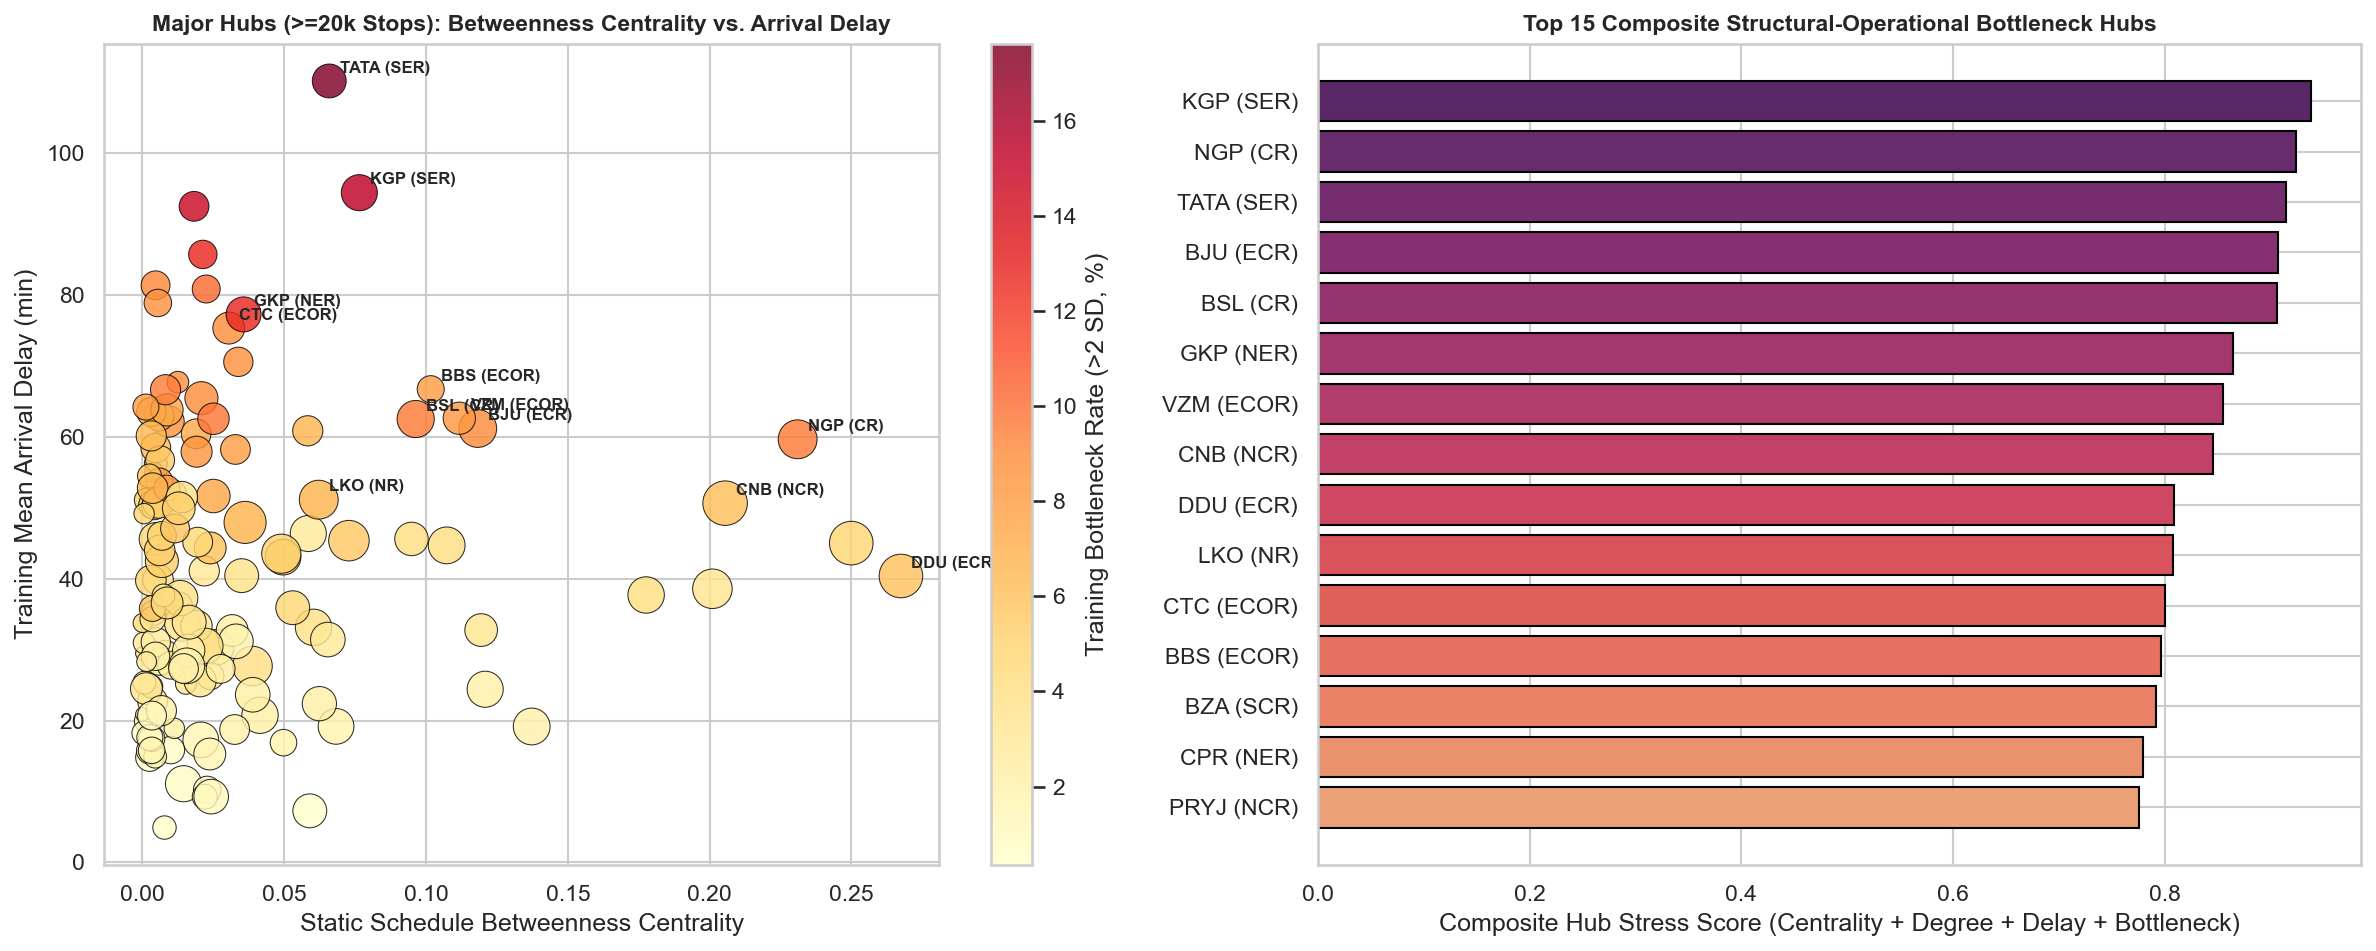

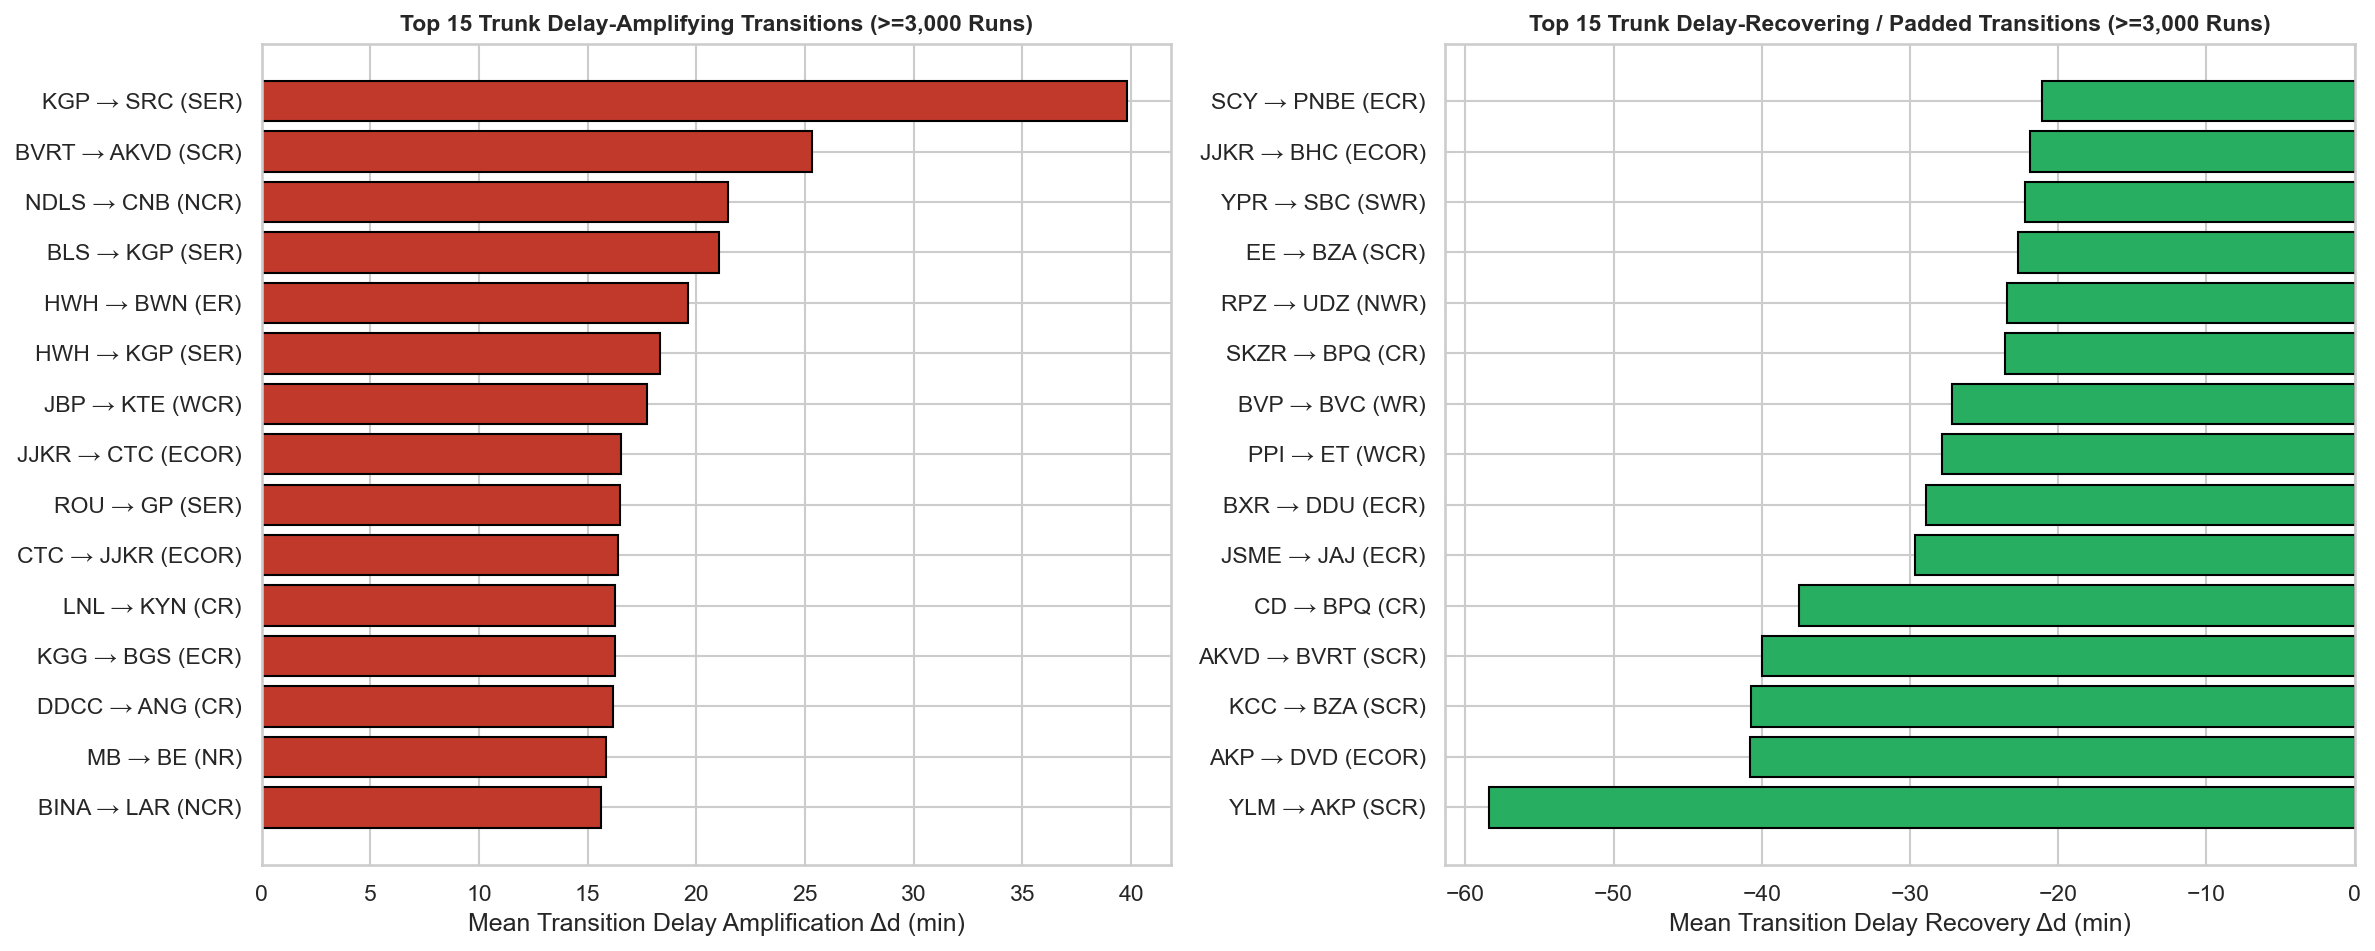

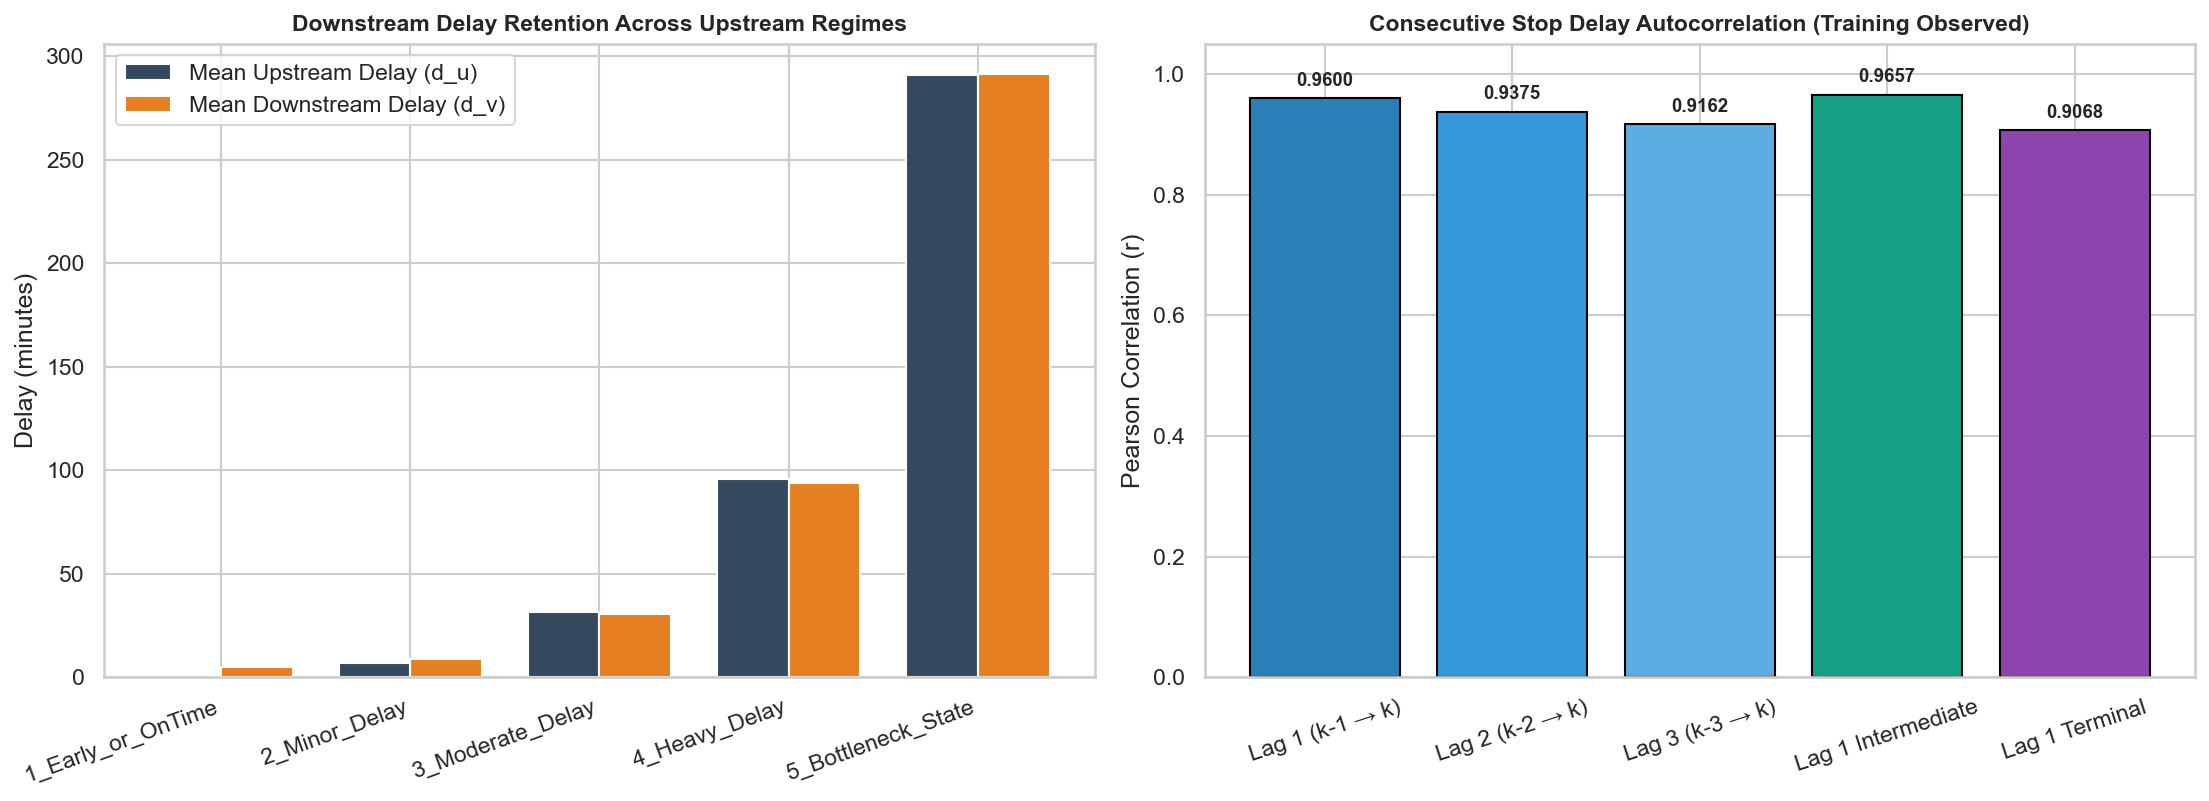

In [17]:
# Visualization 1: Station Structural Centrality vs. Empirical Arrival Delay & Bottleneck Rate (Major Hubs >= 20,000 stops)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

hubs_plot = hubs_ge20k.dropna(subset=["betweenness_centrality", "train_arr_mean_delay_min"]).copy()
sc = axes[0].scatter(
    hubs_plot["betweenness_centrality"],
    hubs_plot["train_arr_mean_delay_min"],
    c=hubs_plot["train_bottleneck_gt_2sd_pct"],
    s=hubs_plot["total_degree"] * 6,
    cmap="YlOrRd",
    alpha=0.82,
    edgecolors="black",
    linewidth=0.5,
)
cbar = plt.colorbar(sc, ax=axes[0])
cbar.set_label("Training Bottleneck Rate (>2 SD, %)")
axes[0].set_title("Major Hubs (>=20k Stops): Betweenness Centrality vs. Arrival Delay", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Static Schedule Betweenness Centrality")
axes[0].set_ylabel("Training Mean Arrival Delay (min)")

# Annotate top composite bottleneck hubs
for row in top25_composite_hubs.head(12).itertuples():
    axes[0].annotate(
        f"{row.station_name} ({row.station_zone})",
        (row.betweenness_centrality, row.train_arr_mean_delay_min),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
        fontweight="bold",
    )

# Right subplot: Top 15 Composite Bottleneck Hubs bar chart
top15_hubs_bar = top25_composite_hubs.head(15).iloc[::-1]
axes[1].barh(
    top15_hubs_bar["station_name"] + " (" + top15_hubs_bar["station_zone"] + ")",
    top15_hubs_bar["composite_hub_stress_score"],
    color=sns.color_palette("flare", len(top15_hubs_bar)),
    edgecolor="black",
)
axes[1].set_title("Top 15 Composite Structural-Operational Bottleneck Hubs", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Composite Hub Stress Score (Centrality + Degree + Delay + Bottleneck)")

plt.tight_layout()
fig1_path = FIG_DIR / "step04_01_station_centrality_vs_bottleneck_stress.png"
plt.savefig(fig1_path, dpi=150)
plt.show()

# Visualization 2: Top 15 Delay-Amplifying vs. Delay-Recovering Directed Transitions (>= 3,000 Trunk Transitions)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

top15_trunk_amp = train_transition_df[train_transition_df["train_obs_transition_count"] >= 3000].sort_values(
    "train_mean_delay_delta_min", ascending=False
).head(15).iloc[::-1]
top15_trunk_rec = train_transition_df[train_transition_df["train_obs_transition_count"] >= 3000].sort_values(
    "train_mean_delay_delta_min", ascending=True
).head(15)

axes[0].barh(
    top15_trunk_amp["from_station"] + " → " + top15_trunk_amp["to_station"] + " (" + top15_trunk_amp["to_station_zone"] + ")",
    top15_trunk_amp["train_mean_delay_delta_min"],
    color="#c0392b",
    edgecolor="black",
)
axes[0].set_title("Top 15 Trunk Delay-Amplifying Transitions (>=3,000 Runs)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Mean Transition Delay Amplification Δd (min)")

axes[1].barh(
    top15_trunk_rec["from_station"] + " → " + top15_trunk_rec["to_station"] + " (" + top15_trunk_rec["to_station_zone"] + ")",
    top15_trunk_rec["train_mean_delay_delta_min"],
    color="#27ae60",
    edgecolor="black",
)
axes[1].set_title("Top 15 Trunk Delay-Recovering / Padded Transitions (>=3,000 Runs)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Mean Transition Delay Recovery Δd (min)")

plt.tight_layout()
fig2_path = FIG_DIR / "step04_01_transition_delay_amplification_vs_recovery.png"
plt.savefig(fig2_path, dpi=150)
plt.show()

# Visualization 3: Conditional Delay Propagation Regimes & Autocorrelation Decay
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

x_labels = [r.split(" ")[0] for r in propagation_regimes_df["upstream_delay_regime"]]
axes[0].bar(
    x_labels,
    propagation_regimes_df["mean_upstream_delay_min"],
    width=0.38,
    label="Mean Upstream Delay (d_u)",
    color="#34495e",
)
axes[0].bar(
    [i + 0.38 for i in range(len(x_labels))],
    propagation_regimes_df["mean_downstream_delay_min"],
    width=0.38,
    label="Mean Downstream Delay (d_v)",
    color="#e67e22",
)
axes[0].set_xticks([i + 0.19 for i in range(len(x_labels))])
axes[0].set_xticklabels(x_labels, rotation=20, ha="right")
axes[0].set_title("Downstream Delay Retention Across Upstream Regimes", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Delay (minutes)")
axes[0].legend()

lags = ["Lag 1 (k-1 → k)", "Lag 2 (k-2 → k)", "Lag 3 (k-3 → k)", "Lag 1 Intermediate", "Lag 1 Terminal"]
corrs = [
    float(propagation_summary_df["r_lag1_all"].iloc[0]),
    float(propagation_summary_df["r_lag2_all"].iloc[0]),
    float(propagation_summary_df["r_lag3_all"].iloc[0]),
    float(propagation_summary_df["r_lag1_intermediate"].iloc[0]),
    float(propagation_summary_df["r_lag1_terminal"].iloc[0]),
]
bars = axes[1].bar(lags, corrs, color=["#2980b9", "#3498db", "#5dade2", "#16a085", "#8e44ad"], edgecolor="black")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Consecutive Stop Delay Autocorrelation (Training Observed)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Pearson Correlation (r)")
axes[1].tick_params(axis="x", rotation=18)
for b in bars:
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, f"{b.get_height():.4f}", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
fig3_path = FIG_DIR / "step04_01_delay_propagation_regimes_and_autocorrelation.png"
plt.savefig(fig3_path, dpi=150)
plt.show()

In [18]:
# Validate exported Parquet artifacts for missingness, uniqueness, and leakage compliance
station_parquet_check = con.execute(f"""
SELECT
    COUNT(*) AS n_rows,
    COUNT(DISTINCT station_name) AS n_unique_stations,
    SUM(CASE WHEN station_name IS NULL THEN 1 ELSE 0 END) AS null_station_keys,
    SUM(CASE WHEN betweenness_centrality IS NULL OR degree_centrality IS NULL THEN 1 ELSE 0 END) AS null_centrality,
    SUM(CASE WHEN train_obs_stops > 0 THEN 1 ELSE 0 END) AS stations_with_train_obs
FROM read_parquet('{station_train_stats_path.as_posix()}');
""").df()

transition_parquet_check = con.execute(f"""
SELECT
    COUNT(*) AS n_rows,
    COUNT(DISTINCT (from_station, to_station)) AS n_unique_edges,
    SUM(CASE WHEN from_station IS NULL OR to_station IS NULL THEN 1 ELSE 0 END) AS null_edge_keys,
    SUM(CASE WHEN train_obs_transition_count > 0 THEN 1 ELSE 0 END) AS edges_with_train_obs
FROM read_parquet('{transition_train_stats_path.as_posix()}');
""").df()

assert int(station_parquet_check["n_rows"].iloc[0]) == int(station_parquet_check["n_unique_stations"].iloc[0])
assert int(transition_parquet_check["n_rows"].iloc[0]) == int(transition_parquet_check["n_unique_edges"].iloc[0])
assert int(station_parquet_check["null_centrality"].iloc[0]) == 0

# Check temporal stability of station mean arrival delay and transition amplification between Train and Full Year
stability_check = con.execute(f"""
SELECT
    ROUND(CORR(train_arr_mean_delay_min, full_arr_mean_delay_min), 4) AS station_mean_delay_train_vs_full_r,
    ROUND(CORR(train_bottleneck_gt_2sd_pct, full_bottleneck_gt_2sd_pct), 4) AS station_bottleneck_train_vs_full_r
FROM read_csv_auto('{(RESULT_DIR / "step04_01_station_network_bottleneck_summary.csv").as_posix()}')
WHERE train_obs_arrival_stops >= 500;
""").df()

findings_payload = {
    "step": "step04_01_network_bottleneck_analysis",
    "chronological_boundaries": {
        "train": [TRAIN_START, TRAIN_END],
        "validation": [VAL_START, VAL_END],
        "test": [TEST_START, TEST_END],
        "partition_summary": partition_audit.to_dict(orient="records"),
    },
    "static_schedule_graph": {
        "n_nodes": int(n_nodes),
        "n_directed_edges": int(n_edges),
        "weakly_connected_components": int(n_wcc),
        "largest_wcc_nodes": int(largest_wcc_size),
        "strongly_connected_components": int(n_scc),
        "largest_scc_nodes": int(largest_scc_size),
    },
    "artifact_validation": {
        "station_stats_parquet": station_parquet_check.to_dict(orient="records")[0],
        "transition_stats_parquet": transition_parquet_check.to_dict(orient="records")[0],
        "temporal_rank_stability_ge500": stability_check.to_dict(orient="records")[0],
    },
    "top10_betweenness_stations": static_station_topology_df.sort_values(
        "betweenness_centrality", ascending=False
    )[["station_name", "station_full_name", "station_zone", "total_degree", "betweenness_centrality"]].head(10).to_dict(orient="records"),
    "top10_composite_bottleneck_hubs": top25_composite_hubs[
        [
            "station_name", "station_full_name", "station_zone",
            "total_degree", "betweenness_centrality", "train_obs_stops",
            "train_arr_mean_delay_min", "train_bottleneck_gt_2sd_pct", "composite_hub_stress_score"
        ]
    ].head(10).to_dict(orient="records"),
    "top10_delay_amplifying_transitions_ge500": top25_amp_transitions[
        [
            "from_station", "to_station", "from_station_zone", "to_station_zone",
            "scheduled_train_count", "train_obs_transition_count",
            "train_from_mean_delay_min", "train_to_mean_delay_min",
            "train_mean_delay_delta_min", "train_median_delay_delta_min", "train_amp_gt_5m_rate"
        ]
    ].head(10).to_dict(orient="records"),
    "top10_trunk_corridor_amplifiers_ge3000": trunk_transitions_ge3000[
        [
            "from_station", "to_station", "from_station_zone", "to_station_zone",
            "scheduled_train_count", "train_obs_transition_count",
            "train_from_mean_delay_min", "train_to_mean_delay_min",
            "train_mean_delay_delta_min", "train_median_delay_delta_min", "train_amp_gt_5m_rate"
        ]
    ].head(10).to_dict(orient="records"),
    "delay_propagation_summary": {
        "lag_autocorrelations": propagation_summary_df.to_dict(orient="records")[0],
        "upstream_regimes": propagation_regimes_df.to_dict(orient="records"),
        "inter_zone_vs_intra_zone": inter_zone_propagation_df.to_dict(orient="records"),
    },
}

findings_path = RESULT_DIR / "step04_01_NETWORK_FINDINGS.json"
with open(findings_path, "w", encoding="utf-8") as f:
    json.dump(findings_payload, f, indent=2)

print("=== STEP 4.1 VALIDATION PASSED ===")
print(f"Exported findings to: {findings_path}")
print(json.dumps(findings_payload["artifact_validation"], indent=2))

=== STEP 4.1 VALIDATION PASSED ===
Exported findings to: D:\M_Tech_CSE_AI\SEM01\DWDM\project\indian_railway_delay\results\step04_01_NETWORK_FINDINGS.json
{
  "station_stats_parquet": {
    "n_rows": 8629,
    "n_unique_stations": 8629,
    "null_station_keys": 0.0,
    "null_centrality": 0.0,
    "stations_with_train_obs": 8136.0
  },
  "transition_stats_parquet": {
    "n_rows": 31514,
    "n_unique_edges": 31514,
    "null_edge_keys": 0.0,
    "edges_with_train_obs": 29079.0
  },
  "temporal_rank_stability_ge500": {
    "station_mean_delay_train_vs_full_r": 0.9952,
    "station_bottleneck_train_vs_full_r": 0.9898
  }
}
